Ready

1. TEXT ENCODING
1(a) UTF-8 bytes : b'Hello from the lab.'
     Byte values : [72, 101, 108, 108, 111, 32, 102, 114, 111, 109, 32, 116, 104, 101, 32, 108, 97, 98, 46]
     Hex         : 48 65 6c 6c 6f 20 66 72 6f 6d 20 74 68 65 20 6c 61 62 2e
1(b) Check: 'H' = 72 = 01001000 | first 8 bits from unpackbits: [0 1 0 0 1 0 0 0]
     All bits (grouped per byte):
     01001000 01100101 01101100 01101100 01101111 00100000 01100110 01110010 01101111 01101101 00100000 01110100 01101000 01100101 00100000 01101100 01100001 01100010 00101110
1(c) Number of bytes = 19, number of bits = 19 x 8 = 152

2. 16-QAM MAPPING
2(a) Padding bits added: 0
     symbol 0: bits 0100 -> (-1-3j)
     symbol 1: bits 1000 -> (3-3j)
     symbol 2: bits 0110 -> (-1+3j)
     symbol 3: bits 0101 -> (-1-1j)
     symbol 4: bits 0110 -> (-1+3j)
     symbol 5: bits 1100 -> (1-3j)
     ...


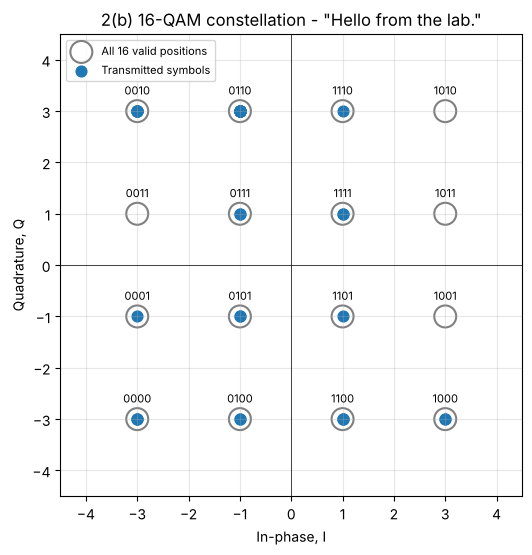

2(c) Number of symbols = 152 / 4 = 38
     Distinct points actually used: 12 of 16

3. PASSBAND MODULATION
3(a) Ns = fs*Ts = 25000000 x 4e-06 = 100 samples per symbol
     t_sym: 0.00 us to 3.96 us in steps of 40 ns
3(b) Real-valued: True, total samples = 38 x 100 = 3800, duration = 152 us


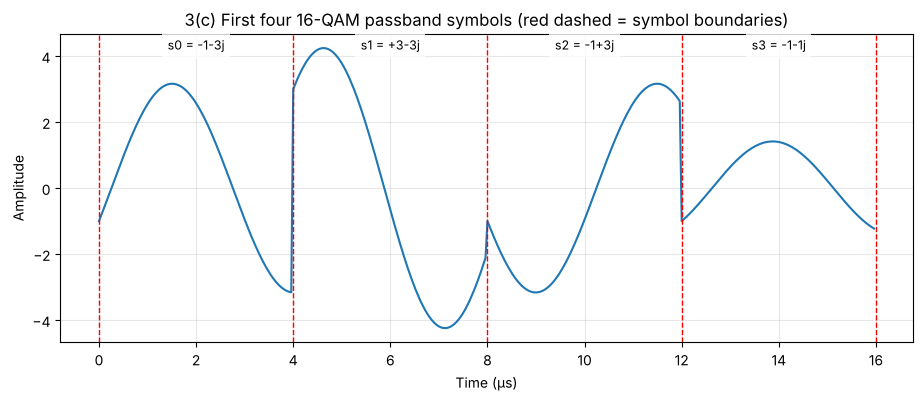

3(d) Symbol rate Rs = 1/Ts = 250,000 symbols/s
     Bit rate    Rb = Rs x 4 = 1,000,000 bit/s
     Carrier cycles per symbol = fc x Ts = 0.80

4. DEMODULATION AND TEXT RECOVERY
4(a) Recovered 38 symbols
      k |   original |        recovered | error
      0 |    (-1-3j) | -0.402-2.965j | 0.599
      1 |     (3-3j) | +3.400-3.696j | 0.803
      2 |    (-1+3j) | -1.499+3.331j | 0.599
      3 |    (-1-1j) | -0.768-0.867j | 0.268
      4 |    (-1+3j) | -1.499+3.331j | 0.599
     Largest error over all symbols: 0.803
     2<cos^2> = 0.951 (ideal 1), 2<sin cos> = 0.183 (ideal 0), 2<sin^2> = 1.049 (ideal 1)
     Formula reproduces the helper's output exactly: True
     Worked, symbol 0: I_hat = 0.951*(-1) - 0.183*(-3) = -0.402
                       Q_hat = -0.183*(-1) + 1.049*(-3) = -2.965
4(b) First 5 decisions:
     -0.402-2.965j -> (-1-3j) -> bits 0100
     +3.400-3.696j -> (3-3j) -> bits 1000
     -1.499+3.331j -> (-1+3j) -> bits 0110
     -0.768-0.867j -> (-1-1j) -> bits 0101
     -1.4

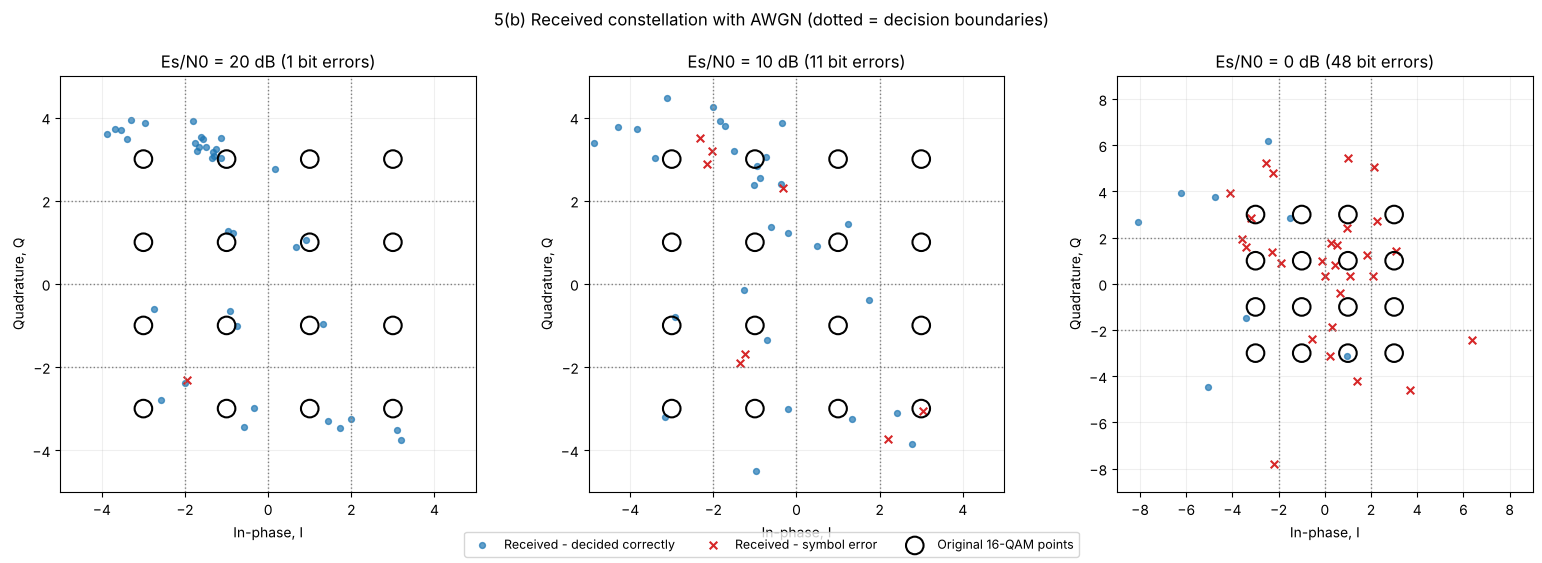


6. (EXTRA) ATTENUATION AND MULTIPATH
Attenuation x0.5 (no AGC)          bit errors =  42, BER = 0.2763, match = False, text = ']u}}\x7fuww\x7f}uu}uu}uw\x7f'
  estimated gain alpha_hat = 0.573 (not exactly 0.5 because Es = 10.84, not 10)
Attenuation x0.5 + AGC             bit errors =   0, BER = 0.0000, match = True, text = 'Hello from the lab.'
Echo delay = 25 samples = 1.0 us, echo phase shift = 72 deg
Multipath (beta=0.4, D=25)         bit errors =   1, BER = 0.0066, match = False, text = 'Hello from the lcb.'
Multipath + AWGN (20 dB)           bit errors =   1, BER = 0.0066, match = False, text = 'Hello!from the lab.'


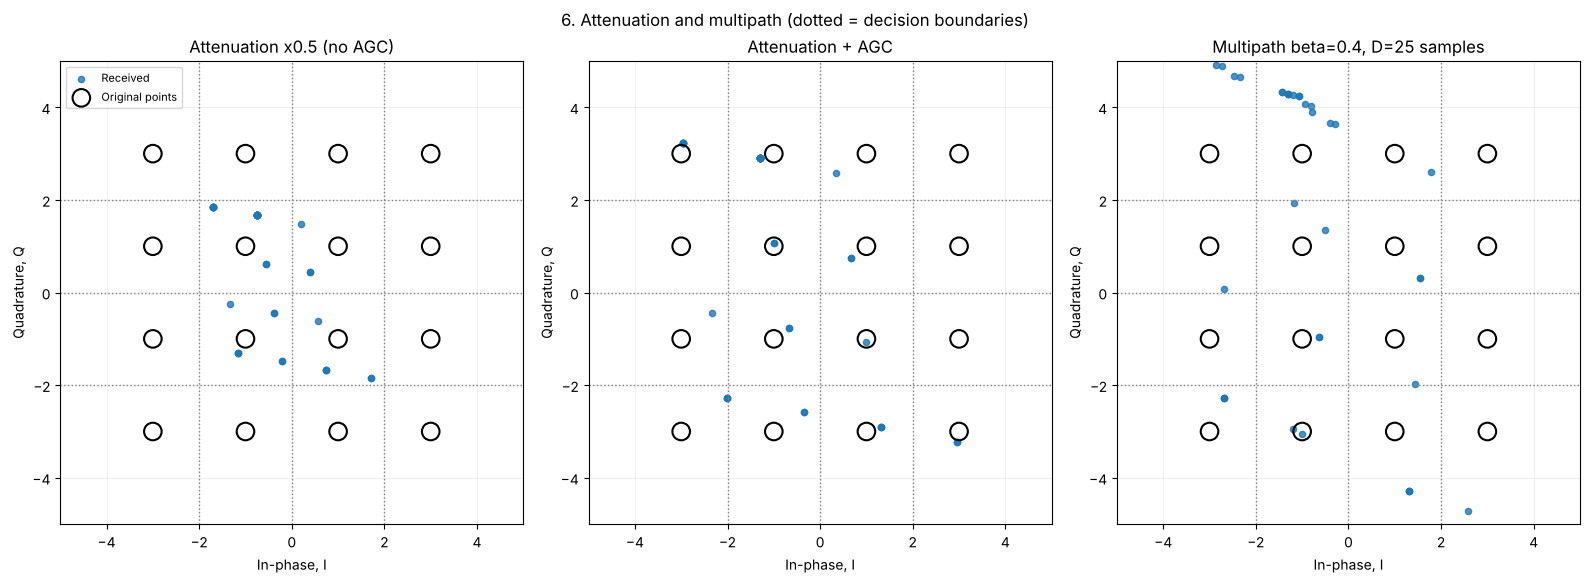


SUMMARY
Bytes / bits            : 19 / 152
Symbols                 : 38 (4 bits each)
Samples per symbol      : 100
Symbol rate / bit rate  : 250 kBd / 1 Mbit/s
Carrier cycles / symbol : 0.8 (not a whole number -> small distortion, but still decodes correctly)
Ideal channel           : 0 bit errors, exact text = True
AWGN 20 dB              :  1 bit errors, BER = 0.0066, exact text = False
AWGN 10 dB              : 11 bit errors, BER = 0.0724, exact text = False
AWGN  0 dB              : 48 bit errors, BER = 0.3158, exact text = False


In [1]:
# =============================================================================
#  DATA COMMUNICATIONS - PRACTICE LAB TEST
#  Text Transmission Using 16-QAM  -  complete worked solution in ONE cell
# =============================================================================
#  Paste this whole cell into Colab/Jupyter and run it. Everything is
#  self-contained: the supplied helper functions are defined below, so no
#  separate qam_receiver_helpers.py file has to be uploaded.
#
#  Every explanation and hand calculation is written as a comment next to the
#  code that performs it, so the whole chain of reasoning can be followed from
#  top to bottom.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from math import erfc, sqrt


# -----------------------------------------------------------------------------
# PROVIDED HELPER CODE (copied exactly from the lab sheet - used as a black box)
# Normally imported with:
#     from qam_receiver_helpers import recover_symbols, add_passband_awgn
# It is defined here instead, so this single cell works with no extra files.
# -----------------------------------------------------------------------------
def recover_symbols(rx_passband, fc, fs, samples_per_symbol):
    """Recover complex I+jQ symbol estimates from a real passband waveform.
    Assumes perfectly aligned symbols/carrier, and a whole number of
    carrier cycles per symbol. Returns one complex value per symbol.
    """
    signal = np.asarray(rx_passband, dtype=float)
    ns = int(samples_per_symbol)
    if ns <= 0 or signal.size % ns != 0:
        raise ValueError("Passband length must be a multiple of samples_per_symbol")
    t = np.arange(ns, dtype=float) / fs
    frames = signal.reshape(-1, ns)
    i = 2 * np.mean(frames * np.cos(2*np.pi*fc*t), axis=1)
    q = -2 * np.mean(frames * np.sin(2*np.pi*fc*t), axis=1)
    return i + 1j*q


def add_passband_awgn(signal, tx_symbols, samples_per_symbol, esn0_db, seed=2026):
    """Add real passband AWGN at a target symbol-energy-to-noise ratio.
    E_s/N_0 (dB) refers to the recovered complex constellation after
    coherent demodulation, not raw sample-level SNR.
    """
    signal = np.asarray(signal, dtype=float)
    symbols = np.asarray(tx_symbols, dtype=complex)
    if symbols.size == 0:
        raise ValueError("tx_symbols must not be empty")
    ns = int(samples_per_symbol)
    if ns <= 0 or signal.size != symbols.size*ns:
        raise ValueError("Expect exactly samples_per_symbol samples per tx symbol")
    es = float(np.mean(np.abs(symbols)**2))
    snr = 10 ** (float(esn0_db) / 10)
    variance = ns * es / (4 * snr)
    rng = np.random.default_rng(seed)
    return signal + rng.normal(0, np.sqrt(variance), size=signal.shape)


# -----------------------------------------------------------------------------
# SETUP (provided)
# -----------------------------------------------------------------------------
# Gray-coded 2-bit -> amplitude map from the lab sheet.
# Neighbouring amplitudes differ in only ONE bit (00 | 01 | 11 | 10), so the
# most likely noise error (sliding to the adjacent level) costs only one bit.
level_map = {'00': -3, '01': -1, '11': 1, '10': 3}
levels = np.array([-3, -1, 1, 3])            # the 4 legal amplitudes per axis

# My addition: the inverse map (amplitude -> 2 bits), which the receiver needs.
inverse_level_map = {v: k for k, v in level_map.items()}

np.set_printoptions(precision=3, suppress=True)
print('Ready')


def heading(title):
    # Small helper that prints a clear section banner in the output.
    print('\n' + '=' * 78 + f'\n{title}\n' + '=' * 78)


# =============================================================================
# 1. TEXT ENCODING
# =============================================================================
# Reasoning:
#  * A computer cannot send characters, only numbers. UTF-8 is the rule that
#    turns each character into one or more bytes (values 0..255).
#  * Every character here is plain ASCII (letters, spaces, a full stop), and
#    an ASCII character takes exactly 1 byte in UTF-8.
#  * Count the characters: "Hello"(5) + " "(1) + "from"(4) + " "(1) + "the"(3)
#    + " "(1) + "lab."(4) = 19 characters -> 19 bytes.
#  * 19 bytes x 8 bits/byte = 152 bits.
#  * Worked example: 'H' has code 72 = 64 + 8 = 2^6 + 2^3, which is 01001000.
heading('1. TEXT ENCODING')

message = "Hello from the lab."

# ---- 1(a) text -> UTF-8 bytes ----
msg_bytes = message.encode('utf-8')          # bytes object, one int per byte
print("1(a) UTF-8 bytes :", msg_bytes)
print("     Byte values :", list(msg_bytes))
print("     Hex         :", msg_bytes.hex(' '))

# ---- 1(b) bytes -> array of 0/1 bits ----
# np.unpackbits splits each uint8 into its 8 bits, most significant bit first
# (MSB-first). The receiver must use the same bit order later.
bits = np.unpackbits(np.frombuffer(msg_bytes, dtype=np.uint8))
bit_str = ''.join(map(str, bits))
print("1(b) Check: 'H' =", msg_bytes[0], "=", format(msg_bytes[0], '08b'),
      "| first 8 bits from unpackbits:", bits[:8])
print("     All bits (grouped per byte):")
print("    ", ' '.join(bit_str[i:i+8] for i in range(0, len(bit_str), 8)))

# ---- 1(c) counts ----
n_bytes = len(msg_bytes)                     # expected 19
n_bits = bits.size                           # expected 19 * 8 = 152
assert n_bits == 8 * n_bytes
print(f"1(c) Number of bytes = {n_bytes}, number of bits = {n_bytes} x 8 = {n_bits}")
# Why the receiver must use the SAME character encoding:
#  * Bits carry no meaning by themselves. The meaning comes from the agreed
#    encoding rule. Decode the same bytes with a different rule and you get
#    different characters, or an error.
#    - UTF-16 reads bytes in PAIRS: the 19 bytes would become ~9 unrelated
#      characters, with 1 leftover byte (a decode error).
#    - For non-ASCII text, 'é' is 2 bytes in UTF-8 (C3 A9). A Latin-1 decoder
#      reads each byte as its own character and shows 'Ã©' ("mojibake").
#  * So TX and RX must agree on: the encoding (UTF-8), the bit order (MSB
#    first), and the 2-bit -> amplitude map. All of these are part of the
#    protocol.


# =============================================================================
# 2. 16-QAM MAPPING AND CONSTELLATION
# =============================================================================
# Reasoning:
#  * 16-QAM has 16 = 2^4 symbols, so each symbol carries log2(16) = 4 bits.
#  * In each 4-bit group b0 b1 b2 b3: (b0 b1) -> I amplitude, (b2 b3) -> Q
#    amplitude, and the symbol is s = I + jQ.
#  * Number of symbols = 152 / 4 = 38 (exact, so no padding is needed).
#  * Worked example, 'H' = 0100 1000:
#        0100 -> I bits 01 -> -1, Q bits 00 -> -3  => s0 = -1 - 3j
#        1000 -> I bits 10 -> +3, Q bits 00 -> -3  => s1 = +3 - 3j
heading('2. 16-QAM MAPPING')

BITS_PER_SYMBOL = 4

# ---- 2(a) group bits in fours and map to complex symbols ----
# Defensive padding up to a multiple of 4 (pad_len = 0 here because
# 152 % 4 == 0). We keep n_bits so the receiver can trim any padding off.
pad_len = (-n_bits) % BITS_PER_SYMBOL
tx_bits = np.concatenate([bits, np.zeros(pad_len, dtype=np.uint8)])
groups = tx_bits.reshape(-1, BITS_PER_SYMBOL)    # row k = 4 bits of symbol k

symbol_list = []
for g in groups:
    I = level_map[f"{g[0]}{g[1]}"]               # first two bits -> I
    Q = level_map[f"{g[2]}{g[3]}"]               # last two bits  -> Q
    symbol_list.append(I + 1j * Q)               # complex symbol I + jQ
symbols = np.array(symbol_list, dtype=complex)

print("2(a) Padding bits added:", pad_len)
for k in range(6):
    print(f"     symbol {k}: bits {''.join(map(str, groups[k]))} -> {symbols[k]}")
print("     ...")

# ---- 2(b) constellation plot ----
# All 16 valid points = every combination of one I level and one Q level.
I_grid, Q_grid = np.meshgrid(levels, levels)
ref_points = (I_grid + 1j * Q_grid).ravel()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(ref_points.real, ref_points.imag, s=250, facecolors='none',
           edgecolors='grey', linewidths=1.5, label='All 16 valid positions')
ax.scatter(symbols.real, symbols.imag, s=60, color='tab:blue',
           label='Transmitted symbols')
for p in ref_points:   # label each point with its 4-bit code (I bits, Q bits)
    code_str = inverse_level_map[int(p.real)] + inverse_level_map[int(p.imag)]
    ax.annotate(code_str, (p.real, p.imag), textcoords='offset points',
                xytext=(0, 12), ha='center', fontsize=8)
ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
ax.set_xlabel('In-phase, I'); ax.set_ylabel('Quadrature, Q')
ax.set_title('2(b) 16-QAM constellation - "Hello from the lab."')
ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5)
ax.set_aspect('equal')                 # square scale, so distances aren't distorted
ax.grid(True, alpha=0.3); ax.legend(loc='upper left', fontsize=8)
plt.show()

# ---- 2(c) ----
print(f"2(c) Number of symbols = {n_bits} / {BITS_PER_SYMBOL} = {symbols.size}")
print(f"     Distinct points actually used: {np.unique(symbols).size} of 16")
# Why 16-QAM carries 4 bits per symbol:
#  With M distinguishable positions, one symbol picks 1 of M possibilities,
#  which is log2(M) bits. Here M = 4 I-levels x 4 Q-levels = 16, and
#  log2(16) = 4. Put another way, 2 bits on I (2^2 = 4 levels) plus 2 bits on
#  Q gives 4 bits.
#  (Not all 16 points appear, because ASCII bytes always start with bit 0,
#   which restricts the first symbol of every byte.)


# =============================================================================
# 3. PASSBAND MODULATION
# =============================================================================
# Unit conversions:
#   fc = 0.2 MHz    = 0.2 x 10^6   = 200 000 Hz
#   fs = 25 000 kHz = 25 000 x 10^3 = 25 000 000 Hz (25 MHz)
#   Ts = 4 us       = 4 x 10^-6 s
# Samples per symbol: Ns = fs * Ts = 25e6 * 4e-6 = 100
# Sample spacing:     1/fs = 40 ns  -> t = 0, 40 ns, ..., 99 x 40 ns = 3.96 us
# Oscillator check:   fs/fc = 25e6 / 2e5 = 125 samples per carrier cycle,
#                     far above the Nyquist minimum of 2.
# Waveform for symbol k (from the sheet):
#   x_k(t) = I_k cos(2*pi*fc*t) - Q_k sin(2*pi*fc*t),  0 <= t < Ts
#   t restarts at 0 for each symbol. The supplied receiver uses the same local
#   time axis for every frame, so we do the same and join the pieces end to end.
heading('3. PASSBAND MODULATION')

# ---- 3(a) time array for one symbol + samples per symbol ----
fc = 0.2e6
fs = 25_000e3
Ts = 4e-6
Ns = int(round(fs * Ts))      # round() first so float error can't truncate 99.999 to 99
t_sym = np.arange(Ns) / fs    # 0 .. (Ns-1)/fs
print(f"3(a) Ns = fs*Ts = {fs:.0f} x {Ts} = {Ns} samples per symbol")
print(f"     t_sym: {t_sym[0]*1e6:.2f} us to {t_sym[-1]*1e6:.2f} us in steps of {1/fs*1e9:.0f} ns")

# ---- 3(b) complete real-valued passband waveform ----
cos_c = np.cos(2 * np.pi * fc * t_sym)   # same for every symbol, so compute once
sin_c = np.sin(2 * np.pi * fc * t_sym)
# Row k of tx_frames = I_k*cos - Q_k*sin. [:, None] turns I/Q into columns so
# they broadcast across the 100 samples of each row.
tx_frames = symbols.real[:, None] * cos_c - symbols.imag[:, None] * sin_c
tx_passband = tx_frames.ravel()           # symbol 0, then symbol 1, ... as one signal
t_total = np.arange(tx_passband.size) / fs
print(f"3(b) Real-valued: {np.isrealobj(tx_passband)}, total samples = "
      f"{symbols.size} x {Ns} = {tx_passband.size}, duration = {tx_passband.size/fs*1e6:.0f} us")

# ---- 3(c) plot the first four symbols with their boundaries marked ----
n_show = 4
seg = slice(0, n_show * Ns)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t_total[seg] * 1e6, tx_passband[seg], lw=1.5, label='Passband x(t)')
for k in range(n_show + 1):                       # boundaries at t = k*Ts
    ax.axvline(k * Ts * 1e6, color='red', ls='--', lw=1)
for k in range(n_show):                           # label each slot with its symbol
    ax.text((k + 0.5) * Ts * 1e6, ax.get_ylim()[1] * 0.9,
            f"s{k} = {int(symbols[k].real):+d}{int(symbols[k].imag):+d}j",
            ha='center', fontsize=9, bbox=dict(fc='white', ec='none', alpha=0.8))
ax.set_xlabel('Time (µs)'); ax.set_ylabel('Amplitude')
ax.set_title('3(c) First four 16-QAM passband symbols (red dashed = symbol boundaries)')
ax.grid(True, alpha=0.3)
plt.show()
# Reading the plot: at the start of each symbol cos = 1 and sin = 0, so the
# waveform starts at I_k (-1, +3, -1, -1). Each symbol is only 0.8 of a carrier
# cycle long, so the waveform jumps at most boundaries.

# ---- 3(d) symbol rate, bit rate, carrier cycles per symbol ----
#   Rs = 1/Ts = 1/4e-6           = 250 000 symbols/s (250 kBd)
#   Rb = Rs x 4                  = 1 000 000 bit/s   (1 Mbit/s)
#   cycles per symbol = fc * Ts  = 2e5 x 4e-6 = 0.8
#   Check: 152 bits / 1 Mbit/s = 152 us = 38 symbols x 4 us
Rs = 1 / Ts
Rb = Rs * BITS_PER_SYMBOL
cycles_per_symbol = fc * Ts
print(f"3(d) Symbol rate Rs = 1/Ts = {Rs:,.0f} symbols/s")
print(f"     Bit rate    Rb = Rs x 4 = {Rb:,.0f} bit/s")
print(f"     Carrier cycles per symbol = fc x Ts = {cycles_per_symbol:.2f}")
# IMPORTANT: the helper's docstring says recover_symbols assumes "a whole
# number of carrier cycles per symbol". 0.8 is NOT a whole number, so the
# recovered symbols should come out slightly wrong even with no noise.
# Question 4 measures and explains this.


# =============================================================================
# 4. DEMODULATION AND TEXT RECOVERY
# =============================================================================
heading('4. DEMODULATION AND TEXT RECOVERY')

# ---- 4(a) call the receiver; compare the first 5 symbols ----
rx_symbols = recover_symbols(tx_passband, fc, fs, Ns)
print(f"4(a) Recovered {rx_symbols.size} symbols")
print(f"     {'k':>2} | {'original':>10} | {'recovered':>16} | error")
for k in range(5):
    print(f"     {k:>2} | {str(symbols[k]):>10} | "
          f"{rx_symbols[k].real:+.3f}{rx_symbols[k].imag:+.3f}j | "
          f"{abs(rx_symbols[k] - symbols[k]):.3f}")
print(f"     Largest error over all symbols: {np.max(np.abs(rx_symbols - symbols)):.3f}")

# Why the noise-free output isn't exact:
#   The receiver multiplies by cos and by -sin, averages over one symbol, and
#   doubles the result. Substituting x = I cos - Q sin gives
#       I_hat =  I*2<cos^2>    - Q*2<sin cos>
#       Q_hat = -I*2<sin cos>  + Q*2<sin^2>
#   With a WHOLE number of cycles: 2<cos^2> = 2<sin^2> = 1 and 2<sin cos> = 0,
#   which gives exact recovery. With 0.8 cycles, the gains are wrong and
#   I and Q leak into each other (crosstalk).
a = 2 * np.mean(cos_c**2)
b = 2 * np.mean(sin_c * cos_c)
c = 2 * np.mean(sin_c**2)
pred = (a*symbols.real - b*symbols.imag) + 1j*(-b*symbols.real + c*symbols.imag)
print(f"     2<cos^2> = {a:.3f} (ideal 1), 2<sin cos> = {b:.3f} (ideal 0), "
      f"2<sin^2> = {c:.3f} (ideal 1)")
print("     Formula reproduces the helper's output exactly:", np.allclose(pred, rx_symbols))
I0, Q0 = symbols[0].real, symbols[0].imag
print(f"     Worked, symbol 0: I_hat = {a:.3f}*({I0:+.0f}) - {b:.3f}*({Q0:+.0f}) = {a*I0 - b*Q0:+.3f}")
print(f"                       Q_hat = -{b:.3f}*({I0:+.0f}) + {c:.3f}*({Q0:+.0f}) = {-b*I0 + c*Q0:+.3f}")
# Will it still decode? The decision thresholds sit halfway between levels
# (-2, 0, +2), so a value decodes correctly while its error is < 1. The
# largest error is ~0.80 < 1, so every symbol still decodes correctly, but
# only ~0.2 of margin is left for noise on the worst symbols. A carrier with a
# whole number of cycles (e.g. fc = 2 MHz -> 8 cycles) would recover exactly.


# ---- 4(b) nearest-level decision + reverse mapping ----
# Rule: for each I (and separately each Q), choose the closest of
# {-3,-1,+1,+3}, which is the same as thresholds at -2, 0, +2.
# Example, symbol 0: I_hat = -0.40. Distances to -3,-1,+1,+3 are
# 2.60, 0.60, 1.40, 3.40, so the closest is -1 -> '01'. Q_hat = -2.97 -> -3 -> '00'.
# That gives bits 0100, the transmitted group.
def nearest_level(values):
    # (N x 4) table of distances to each level; argmin picks the closest one.
    idx = np.argmin(np.abs(values[:, None] - levels[None, :]), axis=1)
    return levels[idx]


def symbols_to_bits(rx):
    # Square grid, so I and Q can be decided independently.
    I_hat = nearest_level(rx.real)
    Q_hat = nearest_level(rx.imag)
    out = []
    for i_amp, q_amp in zip(I_hat, Q_hat):
        # Reverse the map: I bits first, then Q bits (same order as the TX).
        four = inverse_level_map[int(i_amp)] + inverse_level_map[int(q_amp)]
        out.extend(int(ch) for ch in four)
    return np.array(out, dtype=np.uint8), I_hat + 1j * Q_hat


rx_bits_all, decided_symbols = symbols_to_bits(rx_symbols)
print("4(b) First 5 decisions:")
for k in range(5):
    print(f"     {rx_symbols[k].real:+.3f}{rx_symbols[k].imag:+.3f}j -> {decided_symbols[k]}"
          f" -> bits {''.join(map(str, rx_bits_all[4*k:4*k+4]))}")
print("     All symbol decisions correct:", np.array_equal(decided_symbols, symbols))


# ---- 4(c) bits -> bytes -> UTF-8 text ----
def bits_to_text(rx_bits, n_data_bits):
    # Trim to the number of TRANSMITTED DATA bits (this removes any padding).
    data = rx_bits[:n_data_bits]
    rx_bytes = np.packbits(data).tobytes()   # inverse of unpackbits (MSB first)
    # errors='replace' stops a corrupted byte from crashing the noisy runs.
    return rx_bytes, rx_bytes.decode('utf-8', errors='replace')


rx_bytes, rx_text = bits_to_text(rx_bits_all, n_bits)
print("4(c) Recovered bytes:", rx_bytes)
print("     Recovered text :", repr(rx_text))

# ---- 4(d) bit errors + exact-match check ----
bit_errors = int(np.sum(rx_bits_all[:n_bits] != bits))
print(f"4(d) Bit errors = {bit_errors} of {n_bits}, BER = {bit_errors/n_bits:.4f}, "
      f"text recovered exactly: {rx_text == message}")
# Conclusion: 0 bit errors, and the message is recovered exactly. The 0.8-cycle
# distortion bent the constellation, but no point crossed a decision boundary.


# =============================================================================
# 5. ADD CHANNEL NOISE
# =============================================================================
# dB -> linear: snr = 10^(dB/10)  =>  20 dB = 100, 10 dB = 10, 0 dB = 1
# Noise size on the constellation:
#   Es = mean|s|^2 (10.84 for this message; the ideal 16-QAM average is 10).
#   N0 = Es / snr. After demodulation, each axis gets Gaussian noise with
#   variance N0/2. (The helper sets the per-sample variance to Ns*Es/(4*snr).
#   The receiver averages 100 samples and doubles, so the variance becomes
#   (4/Ns^2)*(Ns/2)*Ns*Es/(4*snr) = Es/(2*snr) = N0/2.)
#   So sigma per axis = sqrt(Es/(2*snr)).
#   A decision error needs a push of more than 1 unit (half the level spacing),
#   so 1/sigma tells us how many standard deviations of safety we have.
heading('5. CHANNEL NOISE')

Es = np.mean(np.abs(symbols)**2)
snr_list_db = [20, 10, 0]
print(f"Es = mean|s|^2 = {Es:.3f}")
for snr_db in snr_list_db:
    snr_lin = 10**(snr_db / 10)
    sigma = np.sqrt(Es / (2 * snr_lin))
    print(f"  {snr_db:>2} dB -> linear {snr_lin:>5.0f}, N0 = {Es/snr_lin:6.3f}, "
          f"sigma per axis = {sigma:.3f}, 1/sigma = {1/sigma:.2f}")
# 20 dB: sigma ~0.23, so a boundary is ~4.3 sigma away -> errors rare (ideally).
# 10 dB: sigma ~0.74, a boundary is only ~1.4 sigma away -> a fair number of errors.
#  0 dB: sigma ~2.3, bigger than the level spacing -> decisions near random.

# ---- 5(a) + 5(c) run the three experiments ----
results = {}
for snr_db in snr_list_db:
    rx_pass_noisy = add_passband_awgn(tx_passband, symbols, Ns, snr_db, seed=2026)
    rx_sym = recover_symbols(rx_pass_noisy, fc, fs, Ns)   # same RX chain as Q4
    rx_b_all, decided = symbols_to_bits(rx_sym)
    _, txt = bits_to_text(rx_b_all, n_bits)
    errs = int(np.sum(rx_b_all[:n_bits] != bits))
    results[snr_db] = dict(rx_sym=rx_sym, decided=decided, bit_errors=errs,
                           ber=errs / n_bits, text=txt, match=(txt == message))

print(f"\n5(c) {'Es/N0':>6} | {'bit errors':>10} | {'BER':>7} | match | received text")
for snr_db, r in results.items():
    print(f"     {snr_db:>3} dB | {r['bit_errors']:>10} | {r['ber']:>7.4f} | "
          f"{str(r['match']):>5} | {r['text']!r}")
# BER = incorrect bits / total transmitted bits = bit_errors / 152.
# Expected with seed=2026: 20 dB -> 1/152 = 0.0066 ('Hello$from the lab.',
# where the space 00100000 became 00100100 = '$'); 10 dB -> 11/152 = 0.0724;
# 0 dB -> 48/152 = 0.3158. Only an error-free run gives back the exact text.

# Sanity check against theory: for Gray 16-QAM, each axis is 4-level PAM.
# P(axis crosses a boundary) = (3/2)Q(1/sigma) (2 outer levels have 1
# neighbour, 2 inner levels have 2, which averages 1.5). Gray coding means
# 1 wrong bit out of 2, so BER ~ (3/4)Q(1/sigma). This is rough: it ignores
# the 0.8-cycle distortion, and 152 bits is a small sample.
Qfunc = lambda x: 0.5 * erfc(x / sqrt(2))
for snr_db in snr_list_db:
    sigma = np.sqrt(Es / (2 * 10**(snr_db / 10)))
    print(f"     theory BER at {snr_db:>2} dB ~ {0.75*Qfunc(1/sigma):.4f}  "
          f"(measured {results[snr_db]['ber']:.4f})")

# ---- 5(b) noisy constellations against the original points ----
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, snr_db in zip(axes, snr_list_db):
    r = results[snr_db]
    ok = r['decided'] == symbols                 # correctly decided symbols
    ax.scatter(r['rx_sym'][ok].real, r['rx_sym'][ok].imag, s=18, color='tab:blue',
               alpha=0.7, label='Received - decided correctly')
    ax.scatter(r['rx_sym'][~ok].real, r['rx_sym'][~ok].imag, s=30, color='tab:red',
               marker='x', label='Received - symbol error')
    ax.scatter(ref_points.real, ref_points.imag, s=160, facecolors='none',
               edgecolors='black', linewidths=1.5, label='Original 16-QAM points')
    for th in (-2, 0, 2):                        # decision boundaries
        ax.axvline(th, color='grey', ls=':', lw=1); ax.axhline(th, color='grey', ls=':', lw=1)
    lim = 9 if snr_db == 0 else 5
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
    ax.set_xlabel('In-phase, I'); ax.set_ylabel('Quadrature, Q')
    ax.set_title(f'Es/N0 = {snr_db} dB ({r["bit_errors"]} bit errors)')
    ax.grid(True, alpha=0.2)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=3, fontsize=9)
plt.suptitle('5(b) Received constellation with AWGN (dotted = decision boundaries)', y=1.0)
plt.tight_layout(rect=(0, 0.06, 1, 0.97))
plt.show()

# ---- 5(d) why noisy points sometimes decode as the wrong symbol ----
# The receiver doesn't know what was sent. It only sees where the point
# landed and picks the NEAREST valid point, i.e. the square decision region
# (bounded by -2, 0, +2) the point falls in. AWGN adds a random offset to I
# and Q. Neighbouring points are 2 apart, so a boundary is only 1 unit away.
# If the noise pushes a point more than 1 unit towards a neighbour, it lands
# in the wrong region and is confidently decoded as the wrong symbol.
#  * 20 dB: the noise is small, but the 0.8-cycle distortion had already used
#    up most of the margin on some symbols (only ~0.2 left, < 1 sigma), which
#    explains the single error.
#  * 10 dB: the noise is comparable to the margin, so many points cross.
#  *  0 dB: the noise is larger than the spacing; neighbouring clouds overlap,
#    and decisions are close to guesses.
# Gray coding means most symbol errors (to an adjacent level) cost 1 bit, not
# several. Even so, ONE wrong bit changes a byte, and so a character.


# =============================================================================
# 6. (EXTRA) ATTENUATION AND MULTIPATH
# =============================================================================
# The submission checklist asks for "Attenuation and multipath results", but
# the sheet gives no question or values for them, so the values below are my
# own, clearly stated choices.
heading('6. (EXTRA) ATTENUATION AND MULTIPATH')


def run_chain(rx_pass, label):
    # Full receiver: recover -> decide -> bits -> text, then print a summary.
    rs = recover_symbols(rx_pass, fc, fs, Ns)
    b_all, _ = symbols_to_bits(rs)
    _, txt = bits_to_text(b_all, n_bits)
    errs = int(np.sum(b_all[:n_bits] != bits))
    print(f"{label:<34} bit errors = {errs:>3}, BER = {errs/n_bits:.4f}, "
          f"match = {txt == message}, text = {txt!r}")
    return rs


# ---- 6.1 Attenuation: r(t) = alpha * x(t) ----
# The receiver is linear, so the constellation shrinks by alpha, but the
# thresholds (-2, 0, +2) stay fixed. With alpha = 0.5: the outer level 3 -> 1.5,
# which is < 2, so it decodes as 1 (error). The inner level 1 -> 0.5 still
# decodes as 1 (correct).
# Fix: automatic gain control. Estimate alpha_hat = rms(rx) / sqrt(10) (the
# ideal 16-QAM RMS) and divide it out.
alpha = 0.5                                       # -6 dB (20*log10(0.5) = -6.02 dB)
rs_att = run_chain(alpha * tx_passband, f"Attenuation x{alpha} (no AGC)")
gain = np.sqrt(np.mean(np.abs(rs_att)**2)) / np.sqrt(10)
print(f"  estimated gain alpha_hat = {gain:.3f} (not exactly 0.5 because Es = 10.84, not 10)")
rs_agc = run_chain(alpha * tx_passband / gain, f"Attenuation x{alpha} + AGC")

# ---- 6.2 Multipath: r[n] = x[n] + beta * x[n - D] ----
# beta = 0.4, D = 25 samples = 25 x 40 ns = 1 us (a quarter of a symbol).
#  * ISI: for the first 25 samples of each symbol, the echo still carries the
#    previous symbol.
#  * The echo's carrier phase is shifted by 360 x fc x D/fs = 360 x 0.2 = 72
#    degrees, which rotates it and mixes I into Q.
beta, D = 0.4, 25
echo = np.concatenate([np.zeros(D), tx_passband[:-D]])
rx_mp = tx_passband + beta * echo
print(f"Echo delay = {D} samples = {D/fs*1e6:.1f} us, echo phase shift = {360*fc*D/fs:.0f} deg")
rs_mp = run_chain(rx_mp, f"Multipath (beta={beta}, D={D})")
run_chain(add_passband_awgn(rx_mp, symbols, Ns, 20, seed=2026), "Multipath + AWGN (20 dB)")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (rs, title) in zip(axes, [(rs_att, f'Attenuation x{alpha} (no AGC)'),
                                  (rs_agc, 'Attenuation + AGC'),
                                  (rs_mp, f'Multipath beta={beta}, D={D} samples')]):
    ax.scatter(rs.real, rs.imag, s=20, color='tab:blue', alpha=0.8, label='Received')
    ax.scatter(ref_points.real, ref_points.imag, s=160, facecolors='none',
               edgecolors='black', linewidths=1.5, label='Original points')
    for th in (-2, 0, 2):
        ax.axvline(th, color='grey', ls=':', lw=1); ax.axhline(th, color='grey', ls=':', lw=1)
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5); ax.set_aspect('equal')
    ax.set_xlabel('In-phase, I'); ax.set_ylabel('Quadrature, Q'); ax.set_title(title)
    ax.grid(True, alpha=0.2)
axes[0].legend(loc='upper left', fontsize=8)
plt.suptitle('6. Attenuation and multipath (dotted = decision boundaries)', y=1.0)
plt.tight_layout()
plt.show()
# Interpretation:
#  * Attenuation without AGC pushes the outer points (+/-3) inside the +/-2
#    thresholds, so they are read as +/-1: 42 bit errors with NO noise. AGC
#    restores the grid and gives 0 errors.
#  * Multipath smears and rotates the constellation (ISI + phase rotation).
#    Even this mild echo gives 1 bit error with no noise ('lab' -> 'lcb').
#    Real systems fight this with equalisers, guard intervals/cyclic prefixes
#    (as in OFDM), or by making symbols much longer than the delay spread.


# =============================================================================
# SUMMARY
# =============================================================================
heading('SUMMARY')
print(f"Bytes / bits            : {n_bytes} / {n_bits}")
print(f"Symbols                 : {symbols.size} (4 bits each)")
print(f"Samples per symbol      : {Ns}")
print(f"Symbol rate / bit rate  : {Rs/1e3:.0f} kBd / {Rb/1e6:.0f} Mbit/s")
print(f"Carrier cycles / symbol : {cycles_per_symbol:.1f} (not a whole number -> small "
      f"distortion, but still decodes correctly)")
print(f"Ideal channel           : {bit_errors} bit errors, exact text = {rx_text == message}")
for snr_db, r in results.items():
    print(f"AWGN {snr_db:>2} dB              : {r['bit_errors']:>2} bit errors, "
          f"BER = {r['ber']:.4f}, exact text = {r['match']}")